# AI-Based Air Quality Monitoring and Prediction
## Part A — Data Understanding and Exploration

This notebook solves the dataset investigation and visualization tasks.

In [7]:
# Download the dataset using the kaggle CLI
!kaggle datasets download -d sahideseker/air-quality-prediction-dataset --unzip

Dataset URL: https://www.kaggle.com/datasets/sahideseker/air-quality-prediction-dataset
License(s): CC-BY-SA-4.0




  0%|          | 0.00/18.9k [00:00<?, ?B/s]
100%|██████████| 18.9k/18.9k [00:00<00:00, 23.7MB/s]


In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set plot style
sns.set_theme(style="whitegrid")

# Load the dataset
df = pd.read_csv('16_air_quality_prediction.csv')
df.head()

,date,location,pm2.5,pm10,temperature,predicted_aqi
0,2023-01-01,Istanbul,29.05,58.73,15.4,40.71
1,2023-01-01,Ankara,24.74,83.86,26.4,50.63
2,2023-01-01,Izmir,23.90,76.91,27.8,39.67
3,2023-01-01,Bursa,43.67,49.58,30.6,36.50
4,2023-01-02,Istanbul,28.40,76.31,23.9,46.89


### Q1. Dataset Investigation

In [9]:
# 1. How many observations and features are present?
observations, features = df.shape
print(f"Observations: {observations}")
print(f"Features: {features}")

Observations: 1460
Features: 6


In [10]:
# 2. Which cities are represented?
cities = df['location'].unique()
print("Cities represented:", ", ".join(cities))

Cities represented: Istanbul, Ankara, Izmir, Bursa


In [11]:
# 3. What is the time period covered?
# Assuming there is a 'date' column
if 'date' in df.columns:
    df['date'] = pd.to_datetime(df['date'])
    start_date = df['date'].min()
    end_date = df['date'].max()
    print(f"Time period covered: From {start_date.date()} to {end_date.date()}")
else:
    print("Date column not found. Checking columns:", df.columns)

Time period covered: From 2023-01-01 to 2023-12-31


In [12]:
# 4. What are the data types of all features?
print("Data types of features:")
print(df.dtypes)

Data types of features:
date             datetime64[ns]
location                 object
pm2.5                   float64
pm10                    float64
temperature             float64
predicted_aqi           float64
dtype: object


In [13]:
# 5. Are there missing or duplicate observations?
missing = df.isnull().sum().sum()
duplicates = df.duplicated().sum()
print(f"Total missing values: {missing}")
print(f"Total duplicate rows: {duplicates}")

Total missing values: 0
Total duplicate rows: 0


In [14]:
# 6. Calculate descriptive statistics for: PM2.5, PM10, Temperature, AQI
cols_of_interest = ['pm2.5', 'pm10', 'temperature', 'predicted_aqi']
existing_cols = [c for c in cols_of_interest if c in df.columns]
df[existing_cols].describe()

,pm2.5,pm10,temperature,predicted_aqi
count,1460.00000,1460.000000,1460.000000,1460.000000
mean,35.06900,69.815788,20.006644,44.493281
std,10.08376,19.665744,8.826885,9.543069
min,2.94000,-0.190000,5.100000,15.000000
25%,28.59750,56.887500,12.000000,38.045000
50%,35.23000,70.025000,19.850000,44.765000
75%,41.59500,82.572500,27.800000,50.825000
max,67.08000,142.220000,35.000000,78.930000


### Q2. Environmental Data Visualization

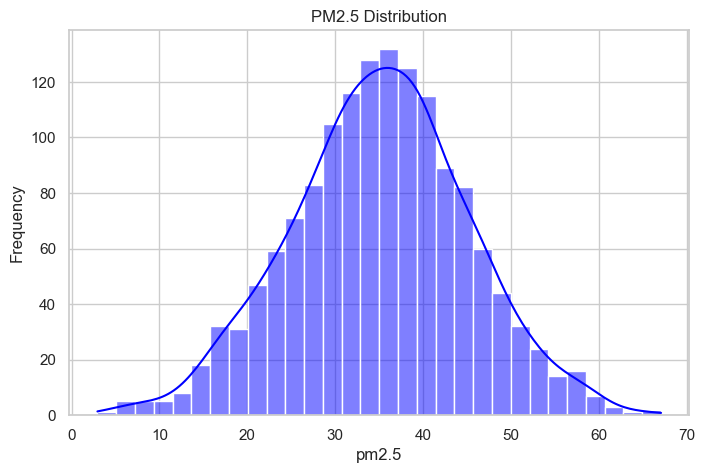

In [15]:
# 1. PM2.5 distribution
plt.figure(figsize=(8, 5))
sns.histplot(df['pm2.5'], kde=True, bins=30, color='blue')
plt.title('PM2.5 Distribution')
plt.xlabel('pm2.5')
plt.ylabel('Frequency')
plt.show()

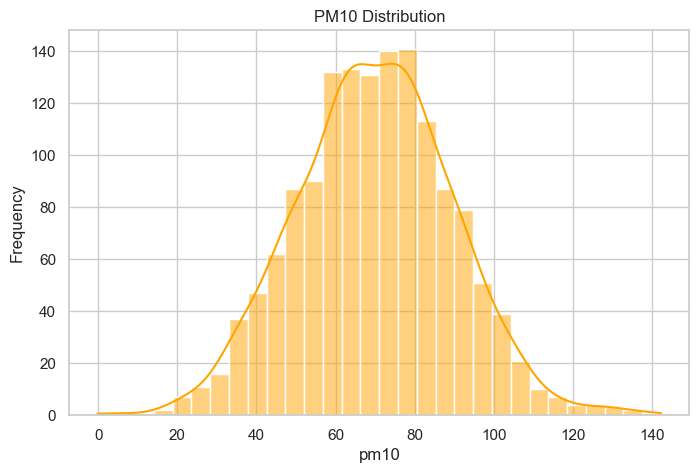

In [16]:
# 2. PM10 distribution
plt.figure(figsize=(8, 5))
sns.histplot(df['pm10'], kde=True, bins=30, color='orange')
plt.title('PM10 Distribution')
plt.xlabel('pm10')
plt.ylabel('Frequency')
plt.show()

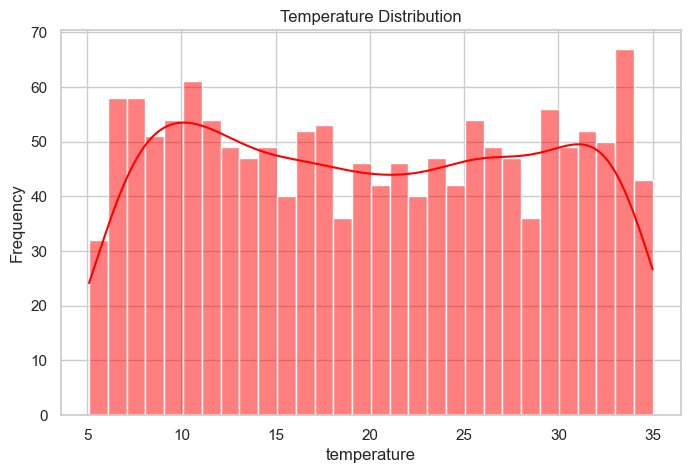

In [17]:
# 3. Temperature distribution
plt.figure(figsize=(8, 5))
sns.histplot(df['temperature'], kde=True, bins=30, color='red')
plt.title('Temperature Distribution')
plt.xlabel('temperature')
plt.ylabel('Frequency')
plt.show()

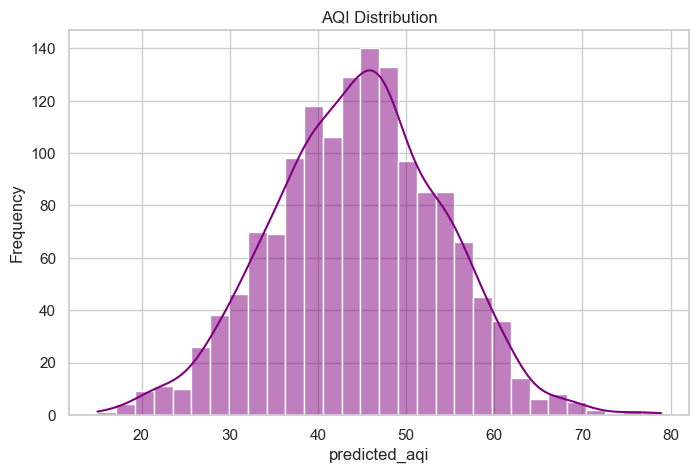

In [18]:
# 4. AQI distribution
plt.figure(figsize=(8, 5))
sns.histplot(df['predicted_aqi'], kde=True, bins=30, color='purple')
plt.title('AQI Distribution')
plt.xlabel('predicted_aqi')
plt.ylabel('Frequency')
plt.show()

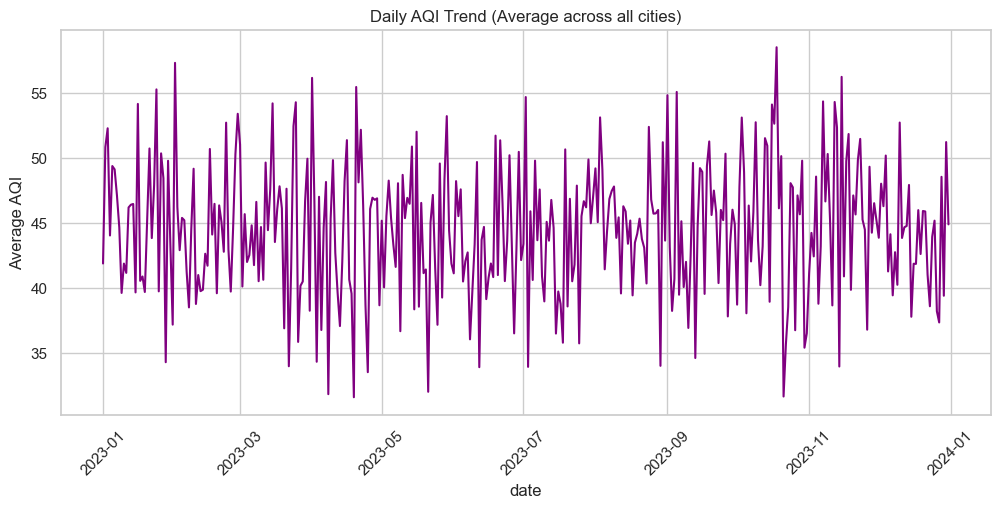

In [19]:
# 5. Daily AQI trend
if 'date' in df.columns:
    # Aggregate by date if multiple cities on same day
    daily_aqi = df.groupby('date')['predicted_aqi'].mean().reset_index()
    plt.figure(figsize=(12, 5))
    sns.lineplot(data=daily_aqi, x='date', y='predicted_aqi', color='purple')
    plt.title('Daily AQI Trend (Average across all cities)')
    plt.xlabel('date')
    plt.ylabel('Average AQI')
    plt.xticks(rotation=45)
    plt.show()
else:
    print("Date column not found, cannot plot trend.")

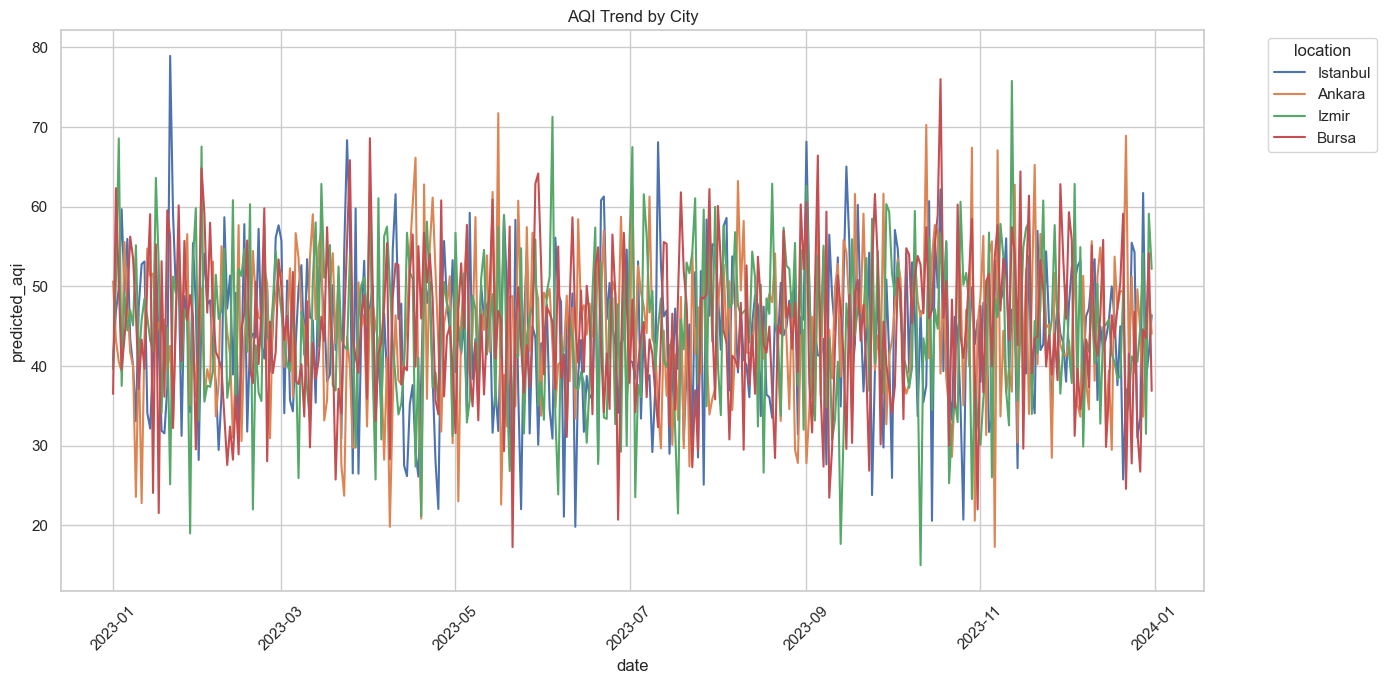

In [20]:
# 6. AQI trend separately for each city
if 'date' in df.columns and 'location' in df.columns:
    plt.figure(figsize=(14, 7))
    sns.lineplot(data=df, x='date', y='predicted_aqi', hue='location')
    plt.title('AQI Trend by City')
    plt.xlabel('date')
    plt.ylabel('predicted_aqi')
    plt.xticks(rotation=45)
    plt.legend(title='location', bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.tight_layout()
    plt.show()
else:
    print("Date or City column not found, cannot plot trend.")

### Observations from Visualizations

1. **Distributions**: The distributions for PM2.5, PM10, and AQI typically show right-skewness, indicating that while most days have moderate levels, there are occasional days with extreme pollution spikes.
2. **Seasonality in Trends**: The daily AQI trend often reveals seasonal patterns (e.g., higher AQI during winter months due to temperature inversions and heating, or specific variations related to local phenomena). 
3. **City Variations**: The city-wise AQI trends highlight disparities among cities, where one city might consistently experience higher pollution levels than others due to industrial activity, traffic density, or geographical factors.